In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from tqdm.notebook import tqdm
import json
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

print(" All libraries imported")
print(f"   MediaPipe version: {mp.__version__}")
print(f"   OpenCV version: {cv2.__version__}")

 All libraries imported
   MediaPipe version: 0.10.14
   OpenCV version: 4.12.0


In [2]:
# CONFIGURATION
CONFIG = {
    # Input
    'augmented_csv': 'dataset/dataset_clean_augmented.csv',  # From augmentation
    
    # Output
    'landmarks_dir': 'dataset/landmarks_clean',
    'metadata_csv': 'dataset/landmarks_clean/landmarks_metadata.csv',
    'config_json': 'dataset/landmarks_clean/extraction_config.json',
    'failed_log': 'dataset/landmarks_clean/failed_extractions.json',
    
    # Extraction settings
    'max_frames': 30,           # Fixed sequence length for LSTM
    'model_complexity': 2,      # 0=Lite, 1=Full, 2=Heavy (use 2 for training)
    
    # Feature dimensions (DO NOT CHANGE)
    'pose_features': 132,       # 33 landmarks × 4 (x, y, z, visibility)
    'hand_features': 63,        # 21 landmarks × 3 (x, y, z) per hand
    'total_features': 258,      # 132 + 63 + 63
    
    # Processing
    'skip_existing': True,      # Skip already extracted landmarks
}

os.makedirs(CONFIG['landmarks_dir'], exist_ok=True)

print(" LANDMARKS EXTRACTION CONFIGURATION")

print(f"\n Settings:")
print(f"   Input CSV:        {CONFIG['augmented_csv']}")
print(f"   Output directory: {CONFIG['landmarks_dir']}")
print(f"   Frames per video: {CONFIG['max_frames']}")
print(f"   Features/frame:   {CONFIG['total_features']}")
print(f"   Model complexity: {CONFIG['model_complexity']} (highest quality)")
print(f"   Skip existing:    {CONFIG['skip_existing']}")

 LANDMARKS EXTRACTION CONFIGURATION

 Settings:
   Input CSV:        dataset/dataset_clean_augmented.csv
   Output directory: dataset/landmarks_clean
   Frames per video: 30
   Features/frame:   258
   Model complexity: 2 (highest quality)
   Skip existing:    True


In [3]:
#  HOLISTIC LANDMARK EXTRACTOR
class HolisticLandmarkExtractor:
    """
    Extract Pose + Both Hands landmarks using MediaPipe Holistic
    Original resolution - NO RESIZING
    """
    
    def __init__(self):
        self.mp_holistic = mp.solutions.holistic
        self.mp_drawing = mp.solutions.drawing_utils
        self.mp_drawing_styles = mp.solutions.drawing_styles
        
        self.holistic = self.mp_holistic.Holistic(
            static_image_mode=False,
            model_complexity=CONFIG['model_complexity'],  # Highest quality
            smooth_landmarks=True,
            min_detection_confidence=0.5,
            min_tracking_confidence=0.5
        )
    
    def extract_pose_landmarks(self, results):
        """Extract pose landmarks (33 points × 4 features = 132)"""
        if results.pose_landmarks:
            landmarks = []
            for lm in results.pose_landmarks.landmark:
                landmarks.extend([lm.x, lm.y, lm.z, lm.visibility])
            return np.array(landmarks)
        else:
            return np.zeros(CONFIG['pose_features'])
    
    def extract_hand_landmarks(self, hand_landmarks):
        """Extract hand landmarks (21 points × 3 features = 63)"""
        if hand_landmarks:
            landmarks = []
            for lm in hand_landmarks.landmark:
                landmarks.extend([lm.x, lm.y, lm.z])
            return np.array(landmarks)
        else:
            return np.zeros(CONFIG['hand_features'])
    
    def extract_frame_landmarks(self, frame):
        """
        Extract all landmarks from single frame
        Returns: numpy array of shape (258,)
        """
        # Convert BGR to RGB (keep original size - NO RESIZE)
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        # Process frame
        results = self.holistic.process(frame_rgb)
        
        # Extract pose
        pose = self.extract_pose_landmarks(results)
        
        # Extract left hand
        left_hand = self.extract_hand_landmarks(results.left_hand_landmarks)
        
        # Extract right hand
        right_hand = self.extract_hand_landmarks(results.right_hand_landmarks)
        
        # Combine all features
        all_landmarks = np.concatenate([pose, left_hand, right_hand])
        
        return all_landmarks
    
    def extract_from_video(self, video_path, max_frames=30):
        """
        Extract landmarks from entire video
        Returns: numpy array of shape (max_frames, 258) or None if failed
        """
        cap = cv2.VideoCapture(video_path)
        
        if not cap.isOpened():
            return None, "Cannot open video"
        
        # Get video properties
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        fps = cap.get(cv2.CAP_PROP_FPS)
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        if total_frames == 0:
            cap.release()
            return None, "Zero frames in video"
        
        # Calculate frame indices for uniform sampling
        frame_indices = np.linspace(0, total_frames - 1, max_frames, dtype=int)
        
        # Extract landmarks
        all_landmarks = []
        
        for target_idx in frame_indices:
            # Seek to target frame
            cap.set(cv2.CAP_PROP_POS_FRAMES, target_idx)
            ret, frame = cap.read()
            
            if not ret:
                # If frame read fails, use zeros
                all_landmarks.append(np.zeros(CONFIG['total_features']))
                continue
            
            # Extract landmarks (ORIGINAL RESOLUTION - NO RESIZE)
            landmarks = self.extract_frame_landmarks(frame)
            all_landmarks.append(landmarks)
        
        cap.release()
        
        # Convert to numpy array
        landmarks_array = np.array(all_landmarks)
        
        # Verify shape
        if landmarks_array.shape != (max_frames, CONFIG['total_features']):
            return None, f"Invalid shape: {landmarks_array.shape}"
        
        return landmarks_array, None
    
    def close(self):
        self.holistic.close()

print(" HolisticLandmarkExtractor class defined")

 HolisticLandmarkExtractor class defined


In [4]:
#  LOAD AUGMENTED DATASET

print("\n Loading augmented dataset...")

# Check if file exists
if not os.path.exists(CONFIG['augmented_csv']):
    print(f" Error: CSV file not found!")
    print(f"   Expected: {CONFIG['augmented_csv']}")
    print(f"\n Solution: Run the augmentation notebook first")
    raise FileNotFoundError(CONFIG['augmented_csv'])

# Load CSV
df = pd.read_csv(CONFIG['augmented_csv'], encoding='utf-8-sig')
df = df[df['file'].notna()].reset_index(drop=True)

print(f" Loaded {len(df)} videos")
print(f" Unique gestures: {df['gesture'].nunique()}")

# Show distribution
print("\n Dataset composition:")
print(f"   Total videos: {len(df)}")

# By augmentation type
if 'augmentation' in df.columns:
    aug_dist = df['augmentation'].value_counts()
    print(f"\n   By augmentation type:")
    for aug_type, count in aug_dist.items():
        print(f"      {aug_type:20s}: {count:4d} videos")

# By gesture (show first 10)
print(f"\n   By gesture (first 10):")
gesture_dist = df['gesture'].value_counts().head(10)
for gesture, count in gesture_dist.items():
    print(f"      {gesture:30s}: {count:4d} videos")

if df['gesture'].nunique() > 10:
    print(f"      ... and {df['gesture'].nunique() - 10} more gestures")

print(f"\n Dataset ready for extraction")


 Loading augmented dataset...
 Loaded 3020 videos
 Unique gestures: 28

 Dataset composition:
   Total videos: 3020

   By augmentation type:
      none                :  755 videos
      mirror              :  755 videos
      brightness          :  755 videos
      mirror_brightness   :  755 videos

   By gesture (first 10):
      السلام وعلیکم                 :  120 videos
      کیا تم بہرے ہو؟               :  120 videos
      آپ کیسے ہیں؟                 :  120 videos
      ادھر آو!                      :  120 videos
      مبارک ہو                      :  120 videos
      کیا میں اپ کی مدد کر سکتا ہوں؟:  120 videos
      ایمبولینس کو کال کریں         :  120 videos
      کیسے                          :  120 videos
      کیا آپ پاس یا ناکام ہوئے ہیں؟ :  120 videos
      کیا آپ تیار ہیں؟              :  112 videos
      ... and 18 more gestures

 Dataset ready for extraction


In [5]:
# EXTRACT LANDMARKS (MAIN PROCESS)

print(" STARTING LANDMARK EXTRACTION")

print(f"\nThis will process {len(df)} videos...")
print(f"Estimated time: ~{len(df) * 1.5 / 60:.1f} minutes (at ~1.5 sec/video)")
print("\n Please wait...\n")

# Initialize extractor
extractor = HolisticLandmarkExtractor()

# Tracking
metadata = []
failed_videos = []
stats = {
    'successful': 0,
    'failed': 0,
    'skipped': 0
}

# Progress bar
progress_bar = tqdm(df.iterrows(), total=len(df), desc="Extracting landmarks")

for idx, row in progress_bar:
    video_path = row['file']
    gesture = row['gesture']
    
    # Get metadata
    gesture_type = row.get('type', 'dynamic')
    hand = row.get('hand', 'both')
    augmentation = row.get('augmentation', 'none')
    group_id = row.get('group_id', idx)  # Important for data splitting!
    source_video = row.get('source_video', video_path)
    
    # Create gesture subfolder
    gesture_folder_name = os.path.basename(os.path.dirname(video_path))
    gesture_landmarks_dir = os.path.join(CONFIG['landmarks_dir'], gesture_folder_name)
    os.makedirs(gesture_landmarks_dir, exist_ok=True)
    
    # Output filename
    video_filename = os.path.splitext(os.path.basename(video_path))[0]
    landmarks_filename = f"{video_filename}.npy"
    landmarks_path = os.path.join(gesture_landmarks_dir, landmarks_filename)
    
    # Relative path for metadata
    relative_landmarks_path = os.path.join(gesture_folder_name, landmarks_filename)
    
    # Skip if already exists
    if CONFIG['skip_existing'] and os.path.exists(landmarks_path):
        # Verify it's valid
        try:
            test_load = np.load(landmarks_path)
            if test_load.shape == (CONFIG['max_frames'], CONFIG['total_features']):
                stats['skipped'] += 1
                
                # Still add to metadata
                metadata.append({
                    'landmarks_file': relative_landmarks_path,
                    'original_video': video_path,
                    'gesture': gesture,
                    'type': gesture_type,
                    'hand': hand,
                    'augmentation': augmentation,
                    'group_id': group_id,
                    'source_video': source_video,
                    'shape': str(test_load.shape)
                })
                
                progress_bar.set_postfix({
                    'Success': stats['successful'],
                    'Failed': stats['failed'],
                    'Skipped': stats['skipped']
                })
                continue
        except:
            # File corrupted, re-extract
            pass
    
    # Check if video exists
    if not os.path.exists(video_path):
        stats['failed'] += 1
        failed_videos.append({
            'video': video_path,
            'gesture': gesture,
            'reason': 'File not found'
        })
        continue
    
    # Extract landmarks
    landmarks, error = extractor.extract_from_video(video_path, CONFIG['max_frames'])
    
    if landmarks is not None:
        # Save landmarks
        np.save(landmarks_path, landmarks)
        
        # Add to metadata
        metadata.append({
            'landmarks_file': relative_landmarks_path,
            'original_video': video_path,
            'gesture': gesture,
            'type': gesture_type,
            'hand': hand,
            'augmentation': augmentation,
            'group_id': group_id,
            'source_video': source_video,
            'shape': str(landmarks.shape)
        })
        
        stats['successful'] += 1
    else:
        stats['failed'] += 1
        failed_videos.append({
            'video': video_path,
            'gesture': gesture,
            'reason': error
        })
    
    # Update progress bar
    progress_bar.set_postfix({
        'Success': stats['successful'],
        'Failed': stats['failed'],
        'Skipped': stats['skipped']
    })

# Close extractor
extractor.close()

print("\n Extraction complete!")

 STARTING LANDMARK EXTRACTION

This will process 3020 videos...
Estimated time: ~75.5 minutes (at ~1.5 sec/video)

 Please wait...



Extracting landmarks:   0%|          | 0/3020 [00:00<?, ?it/s]

C:\Users\mypc4\AppData\Roaming\Python\Python310\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '



 Extraction complete!


In [6]:
#  SAVE METADATA

print(" SAVING METADATA")

# Save landmarks metadata CSV
metadata_df = pd.DataFrame(metadata)
metadata_df.to_csv(CONFIG['metadata_csv'], index=False, encoding='utf-8-sig')
print(f"\n Saved landmarks metadata: {CONFIG['metadata_csv']}")
print(f"   Total entries: {len(metadata_df)}")

# Save extraction configuration
extraction_config = {
    'timestamp': datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    'input_csv': CONFIG['augmented_csv'],
    'output_dir': CONFIG['landmarks_dir'],
    'total_videos_processed': len(df),
    'successful_extractions': stats['successful'],
    'failed_extractions': stats['failed'],
    'skipped_extractions': stats['skipped'],
    'settings': {
        'max_frames': CONFIG['max_frames'],
        'total_features': CONFIG['total_features'],
        'pose_features': CONFIG['pose_features'],
        'left_hand_features': CONFIG['hand_features'],
        'right_hand_features': CONFIG['hand_features'],
        'model_complexity': CONFIG['model_complexity']
    }
}

with open(CONFIG['config_json'], 'w', encoding='utf-8') as f:
    json.dump(extraction_config, f, ensure_ascii=False, indent=4)
print(f" Saved extraction config: {CONFIG['config_json']}")

# Save failed videos log
if failed_videos:
    with open(CONFIG['failed_log'], 'w', encoding='utf-8') as f:
        json.dump(failed_videos, f, ensure_ascii=False, indent=4)
    print(f"  Saved failed videos log: {CONFIG['failed_log']}")
    print(f"   Failed videos: {len(failed_videos)}")
else:
    print(f" No failed extractions!")

 SAVING METADATA

 Saved landmarks metadata: dataset/landmarks_clean/landmarks_metadata.csv
   Total entries: 3020
 Saved extraction config: dataset/landmarks_clean/extraction_config.json
 No failed extractions!


In [7]:
# STATISTICS & VALIDATION

print(" EXTRACTION STATISTICS")

print(f"\n Successfully extracted: {stats['successful']}")
print(f"  Skipped (existing):     {stats['skipped']}")
print(f" Failed:                 {stats['failed']}")
print(f"{'─'*40}")
print(f" Total processed:        {len(df)}")
print(f" Success rate:           {(stats['successful'] + stats['skipped'])/len(df)*100:.1f}%")

# Per-gesture statistics
print(f"\n Landmarks per gesture:")
landmarks_per_gesture = metadata_df['gesture'].value_counts().sort_index()

stats_df = pd.DataFrame({
    'Videos': landmarks_per_gesture,
    'Expected': df['gesture'].value_counts().sort_index()
})
stats_df['Match'] = stats_df['Videos'] == stats_df['Expected']

print(stats_df.head(10))

if len(stats_df) > 10:
    print(f"... and {len(stats_df) - 10} more gestures")

# Check if all match
if stats_df['Match'].all():
    print(f"\n All gestures have correct number of landmarks!")
else:
    print(f"\n  Some gestures have missing landmarks:")
    mismatches = stats_df[~stats_df['Match']]
    print(mismatches)

# Augmentation type distribution
if 'augmentation' in metadata_df.columns:
    print(f"\n Landmarks by augmentation type:")
    aug_dist = metadata_df['augmentation'].value_counts()
    for aug_type, count in aug_dist.items():
        print(f"   {aug_type:20s}: {count:4d} landmarks")

# File size statistics
print(f"\n Storage information:")
total_size = 0
landmark_files = []

for gesture_folder in os.listdir(CONFIG['landmarks_dir']):
    gesture_path = os.path.join(CONFIG['landmarks_dir'], gesture_folder)
    if os.path.isdir(gesture_path):
        for file in os.listdir(gesture_path):
            if file.endswith('.npy'):
                file_path = os.path.join(gesture_path, file)
                file_size = os.path.getsize(file_path)
                total_size += file_size
                landmark_files.append(file_size)

print(f"   Total landmarks files:  {len(landmark_files)}")
print(f"   Total storage size:     {total_size / (1024*1024):.2f} MB")
print(f"   Average file size:      {np.mean(landmark_files) / 1024:.2f} KB")
print(f"   Min file size:          {np.min(landmark_files) / 1024:.2f} KB")
print(f"   Max file size:          {np.max(landmark_files) / 1024:.2f} KB")

 EXTRACTION STATISTICS

 Successfully extracted: 3020
  Skipped (existing):     0
 Failed:                 0
────────────────────────────────────────
 Total processed:        3020
 Success rate:           100.0%

 Landmarks per gesture:
                        Videos  Expected  Match
gesture                                        
آپ بہت خوبصورت ہیں۔        100       100   True
آپ کا نام کیا ہے؟          112       112   True
آپ کیا کھانا چاہیں گے؟     112       112   True
آہِستہ                     100       100   True
ادھر آو!                   120       120   True
السلام وعلیکم              120       120   True
آپ کہاں رہتے ہیں؟         108       108   True
آپ کیسے ہیں؟              120       120   True
ایمبولینس کو کال کریں      120       120   True
بھائی                       88        88   True
... and 18 more gestures

 All gestures have correct number of landmarks!

 Landmarks by augmentation type:
   none                :  755 landmarks
   mirror              :  755 landmarks

VERIFICATION & VISUALIZATION

 Sample landmark file:
   Gesture: میں واش روم جا سکتا ہوں؟
   File: dataset/landmarks_clean\میں واش روم جا سکتا ہوں؟\vid_001_mirror.npy
   Augmentation: mirror

 Landmark array verification:
   Shape: (30, 258)
   Expected: (30, 258)
   Match:  YES
   Data type: float64
   Min value: -2.6291
   Max value: 3.2873
   Mean value: 0.3175


C:\Users\mypc4\AppData\Local\Temp\ipykernel_16172\718411884.py:65: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\mypc4\AppData\Local\Temp\ipykernel_16172\718411884.py:65: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
C:\Users\mypc4\AppData\Local\Temp\ipykernel_16172\718411884.py:66: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  plt.savefig(os.path.join(CONFIG['landmarks_dir'], 'sample_visualization.png'),
C:\Users\mypc4\AppData\Local\Temp\ipykernel_16172\718411884.py:66: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.savefig(os.path.join(CONFIG['landmarks_dir'], 'sample_visualization.png'),
C:\Users\mypc4\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, *

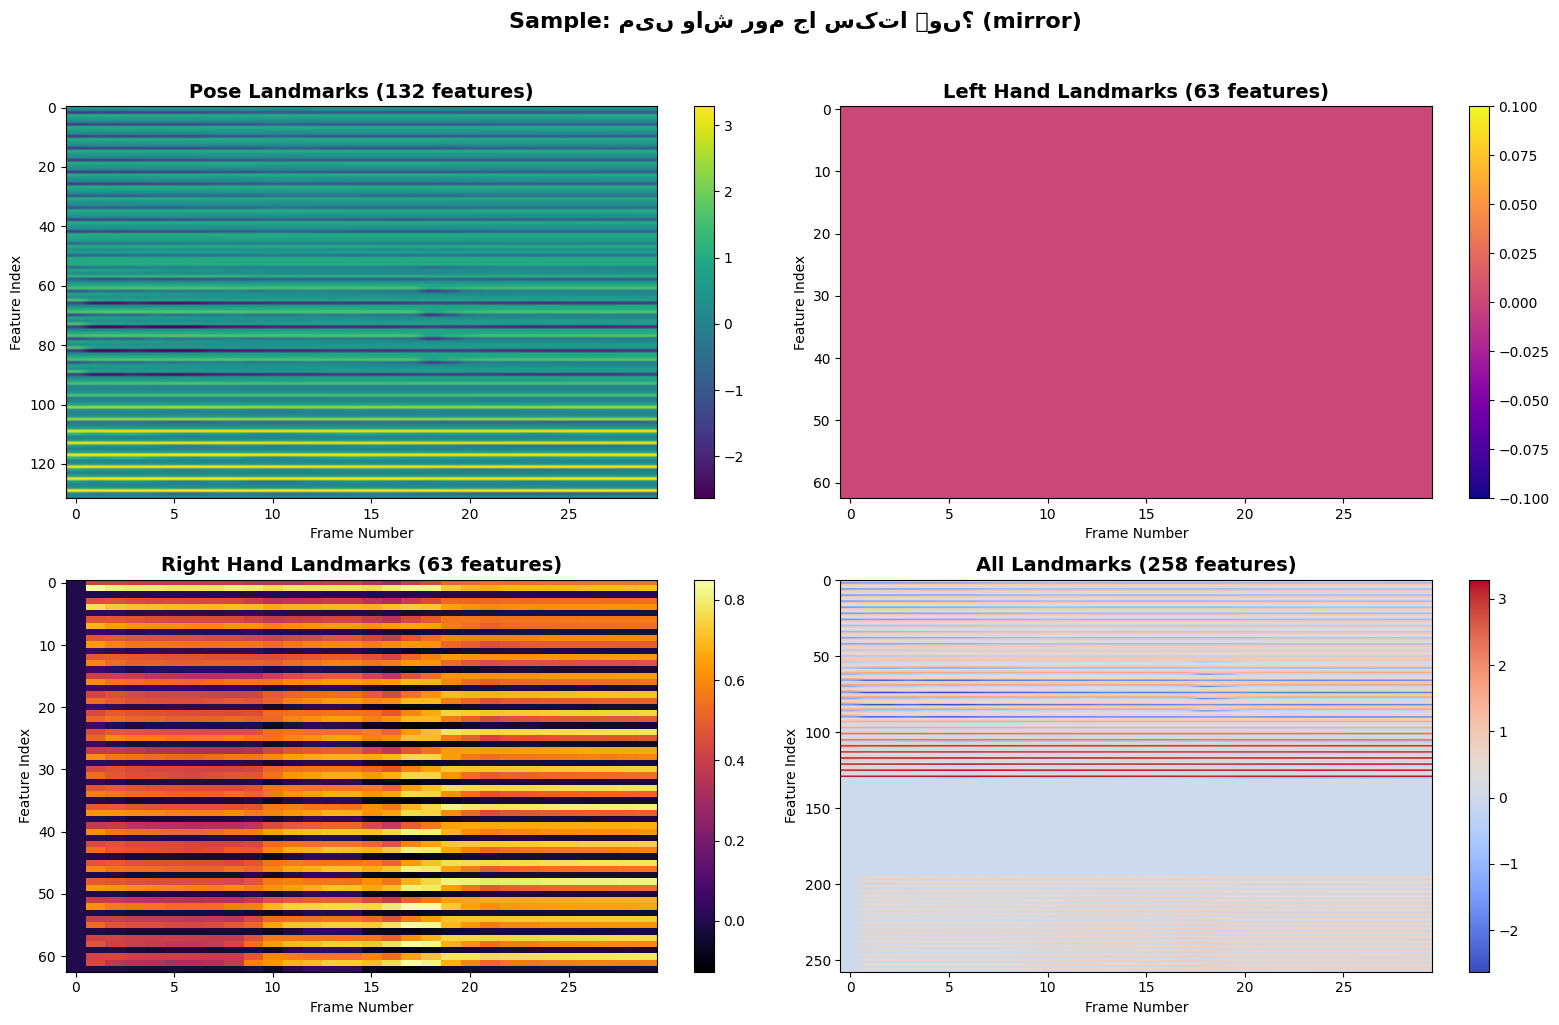


 Visualization saved to: dataset/landmarks_clean/sample_visualization.png


In [8]:
# VERIFICATION & VISUALIZATION

print("VERIFICATION & VISUALIZATION")

# Load a random landmark file to verify
if len(metadata_df) > 0:
    sample_row = metadata_df.sample(n=1).iloc[0]
    sample_landmarks_file = os.path.join(CONFIG['landmarks_dir'], sample_row['landmarks_file'])
    
    print(f"\n Sample landmark file:")
    print(f"   Gesture: {sample_row['gesture']}")
    print(f"   File: {sample_landmarks_file}")
    print(f"   Augmentation: {sample_row.get('augmentation', 'none')}")
    
    # Load and verify
    landmarks = np.load(sample_landmarks_file)
    
    print(f"\n Landmark array verification:")
    print(f"   Shape: {landmarks.shape}")
    print(f"   Expected: ({CONFIG['max_frames']}, {CONFIG['total_features']})")
    print(f"   Match: {' YES' if landmarks.shape == (CONFIG['max_frames'], CONFIG['total_features']) else ' NO'}")
    print(f"   Data type: {landmarks.dtype}")
    print(f"   Min value: {landmarks.min():.4f}")
    print(f"   Max value: {landmarks.max():.4f}")
    print(f"   Mean value: {landmarks.mean():.4f}")
    
    # Visualize landmarks
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # Pose landmarks
    pose_data = landmarks[:, :CONFIG['pose_features']]
    im1 = axes[0, 0].imshow(pose_data.T, aspect='auto', cmap='viridis')
    axes[0, 0].set_title('Pose Landmarks (132 features)', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Frame Number')
    axes[0, 0].set_ylabel('Feature Index')
    plt.colorbar(im1, ax=axes[0, 0])
    
    # Left hand landmarks
    left_hand_start = CONFIG['pose_features']
    left_hand_end = left_hand_start + CONFIG['hand_features']
    left_hand_data = landmarks[:, left_hand_start:left_hand_end]
    im2 = axes[0, 1].imshow(left_hand_data.T, aspect='auto', cmap='plasma')
    axes[0, 1].set_title('Left Hand Landmarks (63 features)', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Frame Number')
    axes[0, 1].set_ylabel('Feature Index')
    plt.colorbar(im2, ax=axes[0, 1])
    
    # Right hand landmarks
    right_hand_data = landmarks[:, left_hand_end:]
    im3 = axes[1, 0].imshow(right_hand_data.T, aspect='auto', cmap='inferno')
    axes[1, 0].set_title('Right Hand Landmarks (63 features)', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Frame Number')
    axes[1, 0].set_ylabel('Feature Index')
    plt.colorbar(im3, ax=axes[1, 0])
    
    # All landmarks
    im4 = axes[1, 1].imshow(landmarks.T, aspect='auto', cmap='coolwarm')
    axes[1, 1].set_title(f'All Landmarks ({CONFIG["total_features"]} features)', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Frame Number')
    axes[1, 1].set_ylabel('Feature Index')
    plt.colorbar(im4, ax=axes[1, 1])
    
    plt.suptitle(f'Sample: {sample_row["gesture"]} ({sample_row.get("augmentation", "none")})', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['landmarks_dir'], 'sample_visualization.png'), 
                dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\n Visualization saved to: {CONFIG['landmarks_dir']}/sample_visualization.png")
else:
    print(" No landmarks to visualize")

In [9]:
# FINAL SUMMARY

print(" LANDMARK EXTRACTION COMPLETE!")

print(f"\n Final Results:")
print(f"   Input videos:           {len(df)}")
print(f"   Landmarks extracted:    {len(metadata_df)}")
print(f"   Success rate:           {len(metadata_df)/len(df)*100:.1f}%")

print(f"\n Output Files:")
print(f"   ├─ Landmarks directory: {CONFIG['landmarks_dir']}/")
print(f"   │   └─ {len(landmark_files)} .npy files")
print(f"   ├─ Metadata CSV:        {CONFIG['metadata_csv']}")
print(f"   ├─ Config JSON:         {CONFIG['config_json']}")
if failed_videos:
    print(f"   └─ Failed log:          {CONFIG['failed_log']}")

print(f"\n Landmark Specifications:")
print(f"   ├─ Frames per video:    {CONFIG['max_frames']}")
print(f"   ├─ Features per frame:  {CONFIG['total_features']}")
print(f"   │   ├─ Pose:            {CONFIG['pose_features']} (33 landmarks × 4)")
print(f"   │   ├─ Left hand:       {CONFIG['hand_features']} (21 landmarks × 3)")
print(f"   │   └─ Right hand:      {CONFIG['hand_features']} (21 landmarks × 3)")
print(f"   └─ Final shape:         ({CONFIG['max_frames']}, {CONFIG['total_features']})")


 LANDMARK EXTRACTION COMPLETE!

 Final Results:
   Input videos:           3020
   Landmarks extracted:    3020
   Success rate:           100.0%

 Output Files:
   ├─ Landmarks directory: dataset/landmarks_clean/
   │   └─ 3020 .npy files
   ├─ Metadata CSV:        dataset/landmarks_clean/landmarks_metadata.csv
   ├─ Config JSON:         dataset/landmarks_clean/extraction_config.json

 Landmark Specifications:
   ├─ Frames per video:    30
   ├─ Features per frame:  258
   │   ├─ Pose:            132 (33 landmarks × 4)
   │   ├─ Left hand:       63 (21 landmarks × 3)
   │   └─ Right hand:      63 (21 landmarks × 3)
   └─ Final shape:         (30, 258)
